In [1]:
import pandas as pd

df_demo = pd.read_csv("data/df_final_demo.txt")
df_demo.head()


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


In [ ]:
df_demo.isna().sum()  client_id, años, edad, genero, balance, logons_

client_id            0
clnt_tenure_yr      14
clnt_tenure_mnth    14
clnt_age            15
gendr               14
num_accts           14
bal                 14
calls_6_mnth        14
logons_6_mnth       14
dtype: int64

In [4]:
df_demo.columns

Index(['client_id', 'clnt_tenure_yr', 'clnt_tenure_mnth', 'clnt_age', 'gendr',
       'num_accts', 'bal', 'calls_6_mnth', 'logons_6_mnth'],
      dtype='str')

In [5]:
df_demo["gendr"].value_counts()

gendr
U    24122
M    23724
F    22746
X        3
Name: count, dtype: int64

In [6]:
df_part1 = pd.read_csv("data/df_final_web_data_pt_1.txt")
df_part1.head()


,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


In [7]:
df_part2 = pd.read_csv("data/df_final_web_data_pt_2.txt")
df_part2.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,763412,601952081_10457207388,397475557_40440946728_419634,confirm,2017-06-06 08:56:00
1,6019349,442094451_91531546617,154620534_35331068705_522317,confirm,2017-06-01 11:59:27
2,6019349,442094451_91531546617,154620534_35331068705_522317,step_3,2017-06-01 11:58:48
3,6019349,442094451_91531546617,154620534_35331068705_522317,step_2,2017-06-01 11:58:08
4,6019349,442094451_91531546617,154620534_35331068705_522317,step_1,2017-06-01 11:57:58


In [8]:
df_part2["process_step"].unique()

<ArrowStringArray>
['confirm', 'step_3', 'step_2', 'step_1', 'start']
Length: 5, dtype: str

In [9]:
df_expe = pd.read_csv("data/df_final_experiment_clients.txt")
df_expe.head()

,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


In [10]:
df_expe.shape

(70609, 2)

In [11]:
df_part1["date_time"] = pd.to_datetime(df_part1["date_time"])

CONCATENAR LA PARTE 1 Y LA PARTE 2

In [12]:
df_web = pd.concat([df_part1, df_part2])

df_web["date_time"] = pd.to_datetime(df_web["date_time"])
df_web = df_web.sort_values(["client_id", "visit_id", "date_time"]).reset_index(drop=True)

df_web.head(10)

,client_id,visitor_id,visit_id,process_step,date_time
0,169,201385055_71273495308,749567106_99161211863_557568,start,2017-04-12 20:19:36
1,169,201385055_71273495308,749567106_99161211863_557568,step_1,2017-04-12 20:19:45
2,169,201385055_71273495308,749567106_99161211863_557568,step_2,2017-04-12 20:20:31
3,169,201385055_71273495308,749567106_99161211863_557568,step_3,2017-04-12 20:22:05
4,169,201385055_71273495308,749567106_99161211863_557568,confirm,2017-04-12 20:23:09
5,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:26:55
6,336,64757908_3400128256,649044751_80905125055_554468,start,2017-06-01 07:42:43
7,546,475037402_89828530214,731811517_9330176838_94847,start,2017-06-17 10:03:29
8,546,475037402_89828530214,731811517_9330176838_94847,step_1,2017-06-17 10:03:39
9,546,475037402_89828530214,731811517_9330176838_94847,step_2,2017-06-17 10:03:52


CANTIDAD DE CLIENTES QUE COMENZARON EL TEST Y LAS QUE LO TERMINARON

In [13]:
clientes_start = df_web[df_web["process_step"] == "start"]["client_id"].nunique()
clientes_confirm = df_web[df_web["process_step"] == "confirm"]["client_id"].nunique()

print(f"Clientes que comenzaron son {clientes_start}")
print(f"Clientes que terminaron son {clientes_confirm}")

Clientes que comenzaron son 118980
Clientes que terminaron son 81145


In [14]:
df_web.columns

Index(['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time'], dtype='str')

CALCULAR LA MEDIA Y LOS CLIENTES QUE HAN TARDADO EN HACER LOS PASOS

In [15]:
df_web = df_web.sort_values(["client_id", "visit_id", "date_time"]).reset_index(drop=True)

# Hora del siguiente evento dentro de la misma visita
df_web["siguiente"] = df_web.groupby(["client_id", "visit_id"])["date_time"].shift(-1)

# Tiempo que pasó en cada paso (hasta el siguiente evento)
df_web["duracion"] = (df_web["siguiente"] - df_web["date_time"]).dt.total_seconds()

# Duración promedio por paso
df_web.groupby("process_step")["duracion"].agg(["mean", "median", "count"])

,mean,median,count
process_step,,,
confirm,247.421603,71.0,14146
start,58.619549,14.0,201708
step_1,60.377922,26.0,149560
step_2,92.403757,63.0,127121
step_3,132.068872,61.0,103758


In [16]:
df_web

,client_id,visitor_id,visit_id,process_step,date_time,siguiente,duracion
0,169,201385055_71273495308,749567106_99161211863_557568,start,2017-04-12 20:19:36,2017-04-12 20:19:45,9.0
1,169,201385055_71273495308,749567106_99161211863_557568,step_1,2017-04-12 20:19:45,2017-04-12 20:20:31,46.0
2,169,201385055_71273495308,749567106_99161211863_557568,step_2,2017-04-12 20:20:31,2017-04-12 20:22:05,94.0
3,169,201385055_71273495308,749567106_99161211863_557568,step_3,2017-04-12 20:22:05,2017-04-12 20:23:09,64.0
4,169,201385055_71273495308,749567106_99161211863_557568,confirm,2017-04-12 20:23:09,NaT,NaN
...,...,...,...,...,...,...,...
755400,9999875,738878760_1556639849,931268933_219402947_599432,step_1,2017-06-01 22:40:08,2017-06-01 22:41:28,80.0
755401,9999875,738878760_1556639849,931268933_219402947_599432,step_1,2017-06-01 22:41:28,2017-06-01 22:41:47,19.0
755402,9999875,738878760_1556639849,931268933_219402947_599432,step_2,2017-06-01 22:41:47,2017-06-01 22:44:58,191.0
755403,9999875,738878760_1556639849,931268933_219402947_599432,step_3,2017-06-01 22:44:58,2017-06-01 22:48:39,221.0


CONTAR LA CANTIDAD LOS QUE ESTAN EN EL TEST

In [17]:
df_expe["Variation"].value_counts()

Variation
Test       26968
Control    23532
Name: count, dtype: int64

CONCATENAR REDUCIR EL DF CON LAS COLUMNAS QUE VAMOS A UTILIZAR

In [18]:
df_demo_reducido = df_demo[["client_id", "clnt_tenure_yr", "clnt_age", "gendr", "bal", "logons_6_mnth"]]

df_demo_reducido.head()

,client_id,clnt_tenure_yr,clnt_age,gendr,bal,logons_6_mnth
0,836976,6.0,60.5,U,45105.30,9.0
1,2304905,7.0,58.0,U,110860.30,9.0
2,1439522,5.0,32.0,U,52467.79,9.0
3,1562045,16.0,49.0,M,67454.65,6.0
4,5126305,12.0,33.0,F,103671.75,3.0


COMBINAR LOS DOS DF

In [19]:
df_demo_var = df_demo_reducido.merge(df_expe, on="client_id", how="inner")

df_demo_var.head()

,client_id,clnt_tenure_yr,clnt_age,gendr,bal,logons_6_mnth,Variation
0,836976,6.0,60.5,U,45105.30,9.0,Test
1,2304905,7.0,58.0,U,110860.30,9.0,Control
2,1439522,5.0,32.0,U,52467.79,9.0,Test
3,1562045,16.0,49.0,M,67454.65,6.0,Test
4,5126305,12.0,33.0,F,103671.75,3.0,Control


AHORA CALCULAR LOS DE TEST Y LOS DE CONTROL

In [20]:
df_test = df_demo_var[df_demo_var["Variation"] == "Test"]
df_control = df_demo_var[df_demo_var["Variation"] == "Control"]


In [ ]:
df_test.head()

,client_id,clnt_tenure_yr,clnt_age,gendr,bal,logons_6_mnth,Variation
0,836976,6.0,60.5,U,45105.30,9.0,Test
2,1439522,5.0,32.0,U,52467.79,9.0,Test
3,1562045,16.0,49.0,M,67454.65,6.0,Test
7,388801,30.0,57.5,M,522498.72,4.0,Test
9,8198645,15.0,54.5,F,382303.83,9.0,Test


In [21]:
df_test.shape

(26968, 7)

In [22]:
df_control.head()

,client_id,clnt_tenure_yr,clnt_age,gendr,bal,logons_6_mnth,Variation
1,2304905,7.0,58.0,U,110860.30,9.0,Control
4,5126305,12.0,33.0,F,103671.75,3.0,Control
5,3727881,5.0,30.5,U,23915.60,3.0,Control
6,272934,5.0,58.5,U,27021.42,5.0,Control
8,285619,30.0,67.5,M,299388.72,6.0,Control


In [23]:
df_control.shape

(23532, 7)

In [24]:
df_control['gendr'].value_counts(dropna=False)

gendr
U      8014
M      7970
F      7543
NaN       5
Name: count, dtype: int64

In [25]:
df_test['gendr'].value_counts(dropna=False)

gendr
U      9266
M      8977
F      8716
NaN       7
X         2
Name: count, dtype: int64

In [26]:
(df_control['gendr'] == 'U').sum()

np.int64(8014)

In [27]:
df_test['gendr'].value_counts(normalize=True) * 100

gendr
U    34.368161
M    33.296243
F    32.328178
X     0.007418
Name: proportion, dtype: float64

## Comprobando la hipotesis de la antiguedad
H0: la antigüedad media (tiempo como cliente de Vanguard) es igual en test y en control.
H1: la antigüedad media es distinta entre los dos grupos.

p-value: 0.0870
No hay una diferencia significativa entre la antigüedad media de los dos grupos.


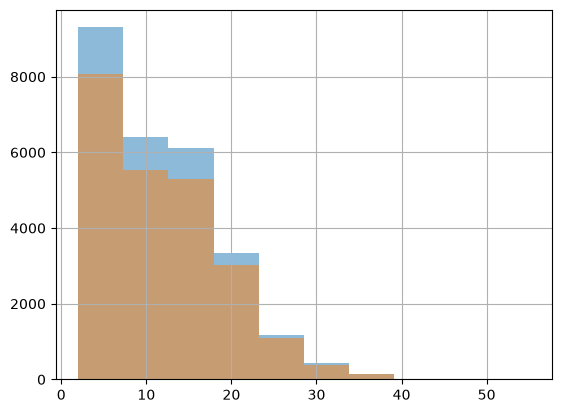

In [28]:
from scipy.stats import ttest_ind

# Hipótesis
## H0: la antigüedad media (tiempo como cliente de Vanguard) es igual en test y en control.
## H1: la antigüedad media es distinta entre los dos grupos.

# Muestras
antiguedad_test = df_test['clnt_tenure_yr'].dropna()
antiguedad_control = df_control['clnt_tenure_yr'].dropna()

# Elección de nivel de significancia: 0.05
alpha = 0.05

# Comprobaciones

antiguedad_test.hist(alpha=0.5, label='control')
antiguedad_control.hist(alpha=0.5, label='test')
# Realizar t-test independiente (equal_var=False por precaución con las varianzas)
resultado = ttest_ind(antiguedad_test, antiguedad_control, equal_var=False)

# Mostrar los resultados
print(f'p-value: {resultado.pvalue:.4f}')

# Interpretación
if resultado.pvalue < alpha:
  print(
      'Hay una diferencia significativa entre la antigüedad media de los'
      ' dos grupos.'
  )
else:
  print(
      'No hay una diferencia significativa entre la antigüedad media de los'
      ' dos grupos.'
  )

## COMPROBANDO LA HIPOTESIS DE LA EDAD
H0: la edad media de los clientes del grupo test es igual a la del grupo control.
H1: la edad media de los clientes del grupo test es distinta a la del grupo control.

p-value: nan
No hay una diferencia significativa entre las edades medias de los dos grupos.


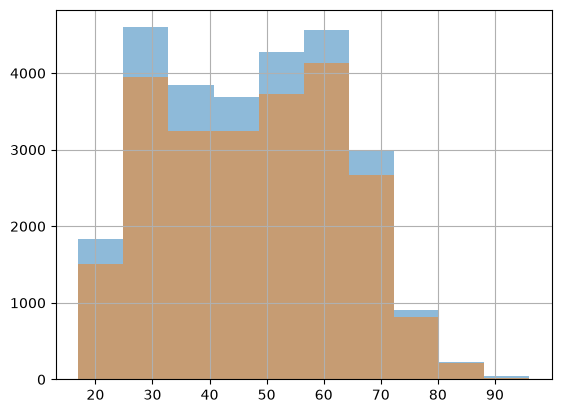

In [29]:
from scipy.stats import ttest_ind

edades_test = df_test['clnt_age']
edades_control = df_control['clnt_age']


alpha = 0.05

edades_test.hist(alpha=0.5, label='control')
edades_control.hist(alpha=0.5, label='test')


resultado = ttest_ind(edades_test, edades_control)


print(f'p-value: {resultado.pvalue:.4f}')

# Interpretación
if resultado.pvalue < alpha:
  print(
      'Hay una diferencia significativa entre las edades medias de los dos grupos.'
  )
else:
  print(
      'No hay una diferencia significativa entre las edades medias de los dos grupos.'
  )

¿Estuvo bien estructurado el experimento?

Sí, en términos generales el experimento estuvo bien estructurado. Se compararon dos grupos, control (diseño antiguo) y test (diseño nuevo), sobre las mismas métricas definidas.   Ambos grupos se observaron en el mismo periodo, un cliente no aparece en ambos grupos para asi evitar que un diseño contamine al otro.  Además, los grupos son comparables en las variables que medimos: la diferencia de edad media es de 0,33 año.     Como matiz, el tamaño de los grupos no es exactamente igual ([46,6 %] control frente a [53,4 %] test). Aun así, las comparaciones se hacen con proporciones y medias, que no dependen de que ambos grupos tengan el mismo tamaño.

¿Se dividió a los clientes de forma aleatoria y equitativa entre los diseños antiguos y los nuevos?

La asignación parece aleatoria respecto a las características de los clientes, pero no fue equitativa en tamaño. Se compararon los dos grupos en edad, antigüedad y género. En conjunto, no hay evidencia de que la asignación estuviera sesgada. Sin embargo, el reparto no es 50/50: el grupo control tiene [46,6 %] de los clientes y el test [53,4 %]

¿Existía algún sesgo?
No se detectó evidencia de sesgo importante en las variables que medimos

¿Fue el plazo del experimento (del 15/03/2017 al 20/06/2017) suficiente para recopilar datos y conclusiones relevantes?

Sí, el plazo fue suficiente. El experimento duró 14 semanas completas (del 15/03/2017 al 20/06/2017), con unos 50.000 clientes en total. Cubrir semanas enteras evita sesgos por día de la semana, y el periodo es lo bastante largo para observar si el efecto del nuevo diseño se mantiene en el tiempo y no solo al principio.

¿Qué otros datos, si estuvieran disponibles, podrían mejorar el análisis?

Varios datos mejorarían el análisis. Contexto técnico (dispositivo, navegador, origen del tráfico) para descartar sesgos de selección. Motivo del abandono o del retroceso, con encuestas o registro de errores, para explicar por qué los clientes se confunden. Resultados posteriores a la confirmación (operaciones completadas, llamadas a soporte, satisfacción) para saber si el nuevo diseño mejora la experiencia real y no solo la finalización